# Mobile manipulation on the LeKiwi: a kiwi base + an SO-101 arm

A fixed-base arm can only touch what is already inside its reach sphere. Bolt
that same arm onto a wheeled base and the reachable set becomes *the whole
floor* — the base carries the arm's workspace to the object. That composition,
**base mobility + arm dexterity**, is *mobile manipulation*, and it is exactly
what the [LeKiwi](https://github.com/SIGRobotics-UIUC/LeKiwi) is: an
[SO-101](https://github.com/TheRobotStudio/SO-ARM100) 6-DOF arm mounted on a
three-omniwheel holonomic base.

This notebook builds the two halves and then *composes* them. The arm is the
real LeKiwi SO-101 from the Jaxterity zoo, carrying the **closed-loop friction
calibration** fitted to the physical robot. The base is a
**kinematic planar holonomic model** we author here as a Jaxonomy
`LeafSystem` — there is no LeKiwi mobile-base URDF in the zoo (a known gap),
so we write the drive kinematics inline from the standard kiwi/omni form.

**By the end you will be able to:**

1. Derive and verify the **kiwi-drive kinematics** — the forward/inverse map
   between a body twist $[v_x, v_y, \omega_z]$ and three wheel speeds — and
   confirm the round-trip is the identity to machine precision.
2. Drive the base **from a start pose to a goal pose** with a proportional
   holonomic controller, simulated through Jaxonomy, and plot the planar path.
3. Drive the SO-101 **end-effector to a Cartesian goal** with a damped
   least-squares IK step built on the MJX kinematic Jacobian, and watch it
   converge.
4. Compose the two into the **combined mobile-manipulation task**: reach an
   object that is *out of the arm's fixed reach from the start*, becomes
   reachable *only because the base drives to it*, and render the result with
   the real SO-101 meshes.

**Reading time** ~25 min · **Runtime** ~3-6 min on CPU (MJX forward kinematics
and a short ODE integration; no training, no contact solve).

> **Out of scope, on purpose.** The base is a **kinematic** model: it has
> *no wheel dynamics, no motor torque limits, no slip, and no contact*. We
> command a body twist and integrate the pose ODE exactly. Wheel speeds are
> reported through the drive map but never *dynamically* tracked. Likewise the
> arm here does pure **kinematic reaching** — no grasping, no contact with the
> object, no payload. The honest claim is *"the geometry of mobile
> manipulation,"* not a dynamics-accurate digital twin of a rolling, grasping
> robot. Where that matters, we say so.

In [1]:
# float64 everywhere: kinematics round-trips and IK residuals are checked to
# ~1e-10, which float32 cannot resolve.
import jax

jax.config.update("jax_enable_x64", True)

import logging  # noqa: E402

logging.getLogger("jaxonomy").setLevel(logging.WARNING)  # quiet the simulator banner

import jax.numpy as jnp  # noqa: E402
import matplotlib as mpl  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import mujoco  # noqa: E402
import numpy as np  # noqa: E402
from jaxonomy import (  # noqa: E402
    DiagramBuilder,
    LeafSystem,
    SimulatorOptions,
    simulate,
)
from mujoco import mjx  # noqa: E402

from jaxterity import zoo  # noqa: E402
from jaxterity.wbc.centroidal import contact_jacobian  # noqa: E402

# Deterministic everything.
RNG = np.random.default_rng(0)
mpl.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 10,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)

print("JAX float64:", jax.config.jax_enable_x64)
print("backend:", jax.default_backend())

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


JAX float64: True
backend: cpu


## 1. The kiwi base and its drive kinematics

A *kiwi drive* (a.k.a. Killough or three-omniwheel drive) places three
omniwheels at $120^\circ$ around the base center. Each omniwheel rolls freely
sideways, so the three together span the full planar twist
$[v_x, v_y, \omega_z]$ — the base is **holonomic**: it can translate in any
direction *and* rotate, independently and simultaneously.

Let wheel $k$ sit at mounting angle $\alpha_k \in \{0^\circ, 120^\circ,
240^\circ\}$, at radius $L$ from the center, with wheel radius $r$. The drive
wheel's rolling direction is tangent to the mounting circle, so the wheel's
signed ground speed for a commanded **body twist** is

$$
v_k \;=\; -\sin\alpha_k\, v_x \;+\; \cos\alpha_k\, v_y \;+\; L\,\omega_z,
\qquad
\omega_k \;=\; \frac{v_k}{r}.
$$

Stacking the three wheels gives the **forward (twist → wheels)** map
$\boldsymbol{\omega} = M\,\boldsymbol{\xi}$ with

$$
M \;=\; \frac{1}{r}
\begin{bmatrix}
-\sin\alpha_1 & \cos\alpha_1 & L\\
-\sin\alpha_2 & \cos\alpha_2 & L\\
-\sin\alpha_3 & \cos\alpha_3 & L
\end{bmatrix},
\qquad
\boldsymbol{\xi} = \begin{bmatrix} v_x\\ v_y\\ \omega_z\end{bmatrix},
\qquad
\boldsymbol{\omega} = \begin{bmatrix}\omega_1\\\omega_2\\\omega_3\end{bmatrix}.
$$

Because the three wheels are linearly independent (the $120^\circ$ spacing makes
$M$ full rank), $M$ is invertible and the **inverse (wheels → twist)** map is
just $\boldsymbol{\xi} = M^{-1}\boldsymbol{\omega}$. We check below that
$M^{-1}M = I$ and that the round-trip $\boldsymbol{\xi}\!\to\!\boldsymbol{\omega}
\!\to\!\boldsymbol{\xi}$ is the identity to machine precision.

In [2]:
WHEEL_ANGLES = jnp.deg2rad(jnp.array([0.0, 120.0, 240.0]))  # alpha_k
L = 0.125  # m, wheel mounting radius from base center
R = 0.05  # m, wheel radius


def kiwi_matrix(angles=WHEEL_ANGLES, L=L, r=R):
    """Drive matrix M (3x3): body twist [vx, vy, wz] -> wheel speeds [rad/s]."""
    rows = jnp.stack(
        [-jnp.sin(angles), jnp.cos(angles), L * jnp.ones_like(angles)], axis=1
    )
    return rows / r


M = kiwi_matrix()
M_inv = jnp.linalg.inv(M)


def forward_kiwi(twist):
    return M @ twist  # twist  -> wheel speeds


def inverse_kiwi(wheels):
    return M_inv @ wheels  # wheels -> twist


# --- round-trip identity over many random twists -> GATE ---
twists = RNG.uniform(-1.0, 1.0, size=(2000, 3))
roundtrip = (M_inv @ (M @ twists.T)).T
rt_err = float(np.max(np.linalg.norm(roundtrip - twists, axis=1)))
det_M = float(jnp.linalg.det(M))
i_err = float(jnp.max(jnp.abs(M_inv @ M - jnp.eye(3))))

print(f"det(M)                 = {det_M:.4f}   (nonzero -> invertible)")
print(f"max |M^-1 M - I|       = {i_err:.2e}")
print(f"max round-trip error   = {rt_err:.2e}   over {len(twists)} random twists")
assert rt_err < 1e-10, f"round-trip not identity: {rt_err}"
assert det_M != 0.0
print("GATE round-trip identity: PASS")

det(M)                 = 2598.0762   (nonzero -> invertible)
max |M^-1 M - I|       = 4.07e-16
max round-trip error   = 9.50e-16   over 2000 random twists
GATE round-trip identity: PASS


**Figure 1** visualizes the geometry (the three wheels at $120^\circ$ and the
direction each one drives) and confirms the round-trip numerically: commanded
twists versus the twists recovered after passing through wheel space lie exactly
on the diagonal.

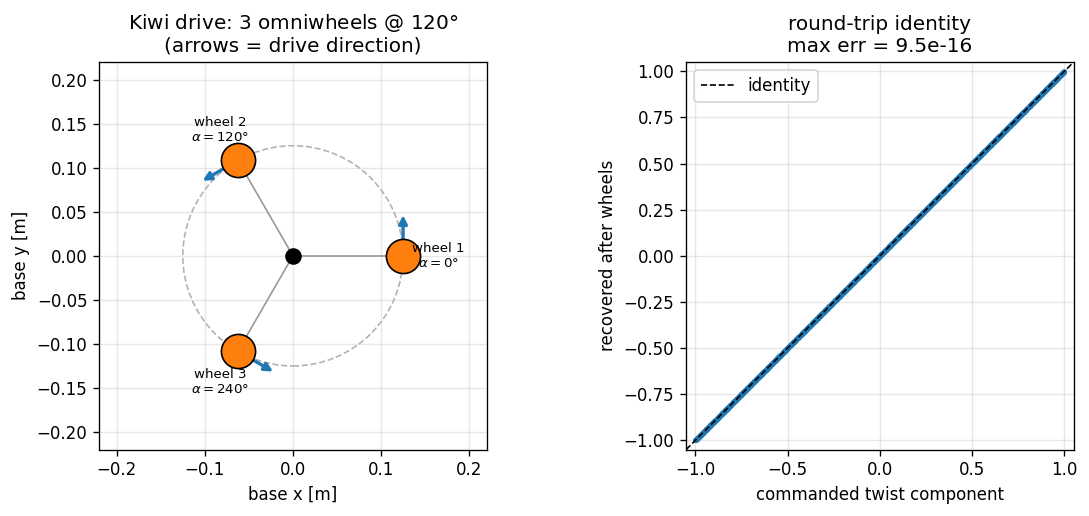

In [3]:
fig, (axg, axr) = plt.subplots(1, 2, figsize=(10, 4.4))

# --- left: base geometry ---
ang = np.asarray(WHEEL_ANGLES)
for k, a in enumerate(ang):
    px, py = L * np.cos(a), L * np.sin(a)
    axg.plot([0, px], [0, py], color="0.6", lw=1, zorder=1)
    # drive direction = tangent (-sin a, cos a)
    dx, dy = -np.sin(a), np.cos(a)
    axg.annotate(
        "",
        xy=(px + 0.05 * dx, py + 0.05 * dy),
        xytext=(px, py),
        arrowprops=dict(arrowstyle="-|>", color="C0", lw=2),
    )
    axg.scatter([px], [py], s=420, color="C1", edgecolor="k", zorder=3)
    axg.text(
        px * 1.32,
        py * 1.32,
        f"wheel {k + 1}\n$\\alpha={int(round(np.degrees(a)))}\\degree$",
        ha="center",
        va="center",
        fontsize=8,
    )
axg.scatter([0], [0], s=80, color="k", zorder=4)
axg.add_patch(plt.Circle((0, 0), L, fill=False, ls="--", color="0.7"))
axg.set_aspect("equal")
axg.set_xlim(-0.22, 0.22)
axg.set_ylim(-0.22, 0.22)
axg.set_title("Kiwi drive: 3 omniwheels @ 120$\\degree$\n(arrows = drive direction)")
axg.set_xlabel("base x [m]")
axg.set_ylabel("base y [m]")

# --- right: round-trip identity ---
axr.scatter(twists.ravel(), roundtrip.ravel(), s=4, alpha=0.3, color="C0")
lim = [-1.05, 1.05]
axr.plot(lim, lim, "k--", lw=1, label="identity")
axr.set_xlim(lim)
axr.set_ylim(lim)
axr.set_aspect("equal")
axr.set_xlabel("commanded twist component")
axr.set_ylabel("recovered after wheels")
axr.set_title(f"round-trip identity\nmax err = {rt_err:.1e}")
axr.legend(loc="upper left")
fig.tight_layout()
plt.show()

> **Figure 1.** *Left:* the kiwi base geometry — three omniwheels at
> $\alpha_k \in \{0^\circ, 120^\circ, 240^\circ\}$, radius $L = 0.125$ m,
> each arrow showing the direction that wheel drives. *Right:* the
> forward/inverse drive map is a clean bijection — commanded twist components
> versus the values recovered after a full $\boldsymbol{\xi}\to\boldsymbol{\omega}
> \to\boldsymbol{\xi}$ round-trip fall on the identity line (max error
> $\approx$ the printed value, machine precision).

## 2. Base navigation: driving to a goal pose

We model the base as a **kinematic planar holonomic body** with pose
$\mathbf{q} = [x, y, \theta]$ in the world frame. A commanded **body** twist
$[v_x, v_y, \omega_z]$ integrates as

$$
\dot x = v_x\cos\theta - v_y\sin\theta,\qquad
\dot y = v_x\sin\theta + v_y\cos\theta,\qquad
\dot\theta = \omega_z,
$$

i.e. the rotation matrix $R(\theta)$ maps the body-frame linear velocity into
the world frame, and the body yaw rate is the world yaw rate. We implement this
as a Jaxonomy `LeafSystem` (`KiwiBase`) whose continuous state is the pose and
whose input port is the body twist.

A second `LeafSystem` (`HolonomicController`) closes a simple **proportional**
loop: it reads the pose, rotates the world-frame position error into the body
frame, and emits a clamped twist $[\,k_p\,e_x^{\text{body}},\,k_p\,e_y^{\text{body}},\,
k_\theta\,e_\theta\,]$. Wired together in a `DiagramBuilder` and simulated with
Jaxonomy's adaptive ODE solver, the base converges to the goal pose. (This is a
*kinematic* controller — there is no mass, so there is no overshoot from
inertia; the only dynamics are the pose integrator.)

In [4]:
class KiwiBase(LeafSystem):
    """Kinematic planar holonomic base. State [x,y,theta]; input body twist."""

    def __init__(self):
        super().__init__(name="kiwi_base")
        self.declare_continuous_state(default_value=jnp.zeros(3), ode=self._ode)
        self.declare_input_port(name="twist")  # [vx,vy,wz] body frame
        self.declare_output_port(self._out, name="pose", requires_inputs=False)

    def _ode(self, time, state, *inputs):
        x, y, th = state.continuous_state
        vx, vy, wz = inputs[0]
        return jnp.array(
            [
                vx * jnp.cos(th) - vy * jnp.sin(th),
                vx * jnp.sin(th) + vy * jnp.cos(th),
                wz,
            ]
        )

    def _out(self, time, state, *inputs):
        return state.continuous_state


class HolonomicController(LeafSystem):
    """Proportional pose controller -> body twist toward a goal pose."""

    def __init__(self, goal, kp_lin=1.5, kp_ang=2.0, v_max=0.6, w_max=1.5):
        super().__init__(name="holonomic_ctrl")
        self.goal = jnp.asarray(goal)
        self.kp_lin, self.kp_ang = kp_lin, kp_ang
        self.v_max, self.w_max = v_max, w_max
        self.declare_input_port(name="pose")
        self.declare_output_port(self._out, name="twist", requires_inputs=True)

    def _out(self, time, state, *inputs):
        x, y, th = inputs[0]
        ex, ey = self.goal[0] - x, self.goal[1] - y
        c, s = jnp.cos(th), jnp.sin(th)
        bx, by = c * ex + s * ey, -s * ex + c * ey  # world error -> body frame
        eth = jnp.arctan2(jnp.sin(self.goal[2] - th), jnp.cos(self.goal[2] - th))
        return jnp.array(
            [
                jnp.clip(self.kp_lin * bx, -self.v_max, self.v_max),
                jnp.clip(self.kp_lin * by, -self.v_max, self.v_max),
                jnp.clip(self.kp_ang * eth, -self.w_max, self.w_max),
            ]
        )


def drive_base(goal, t_end=14.0):
    """Simulate the closed-loop base from the origin to `goal`; return time, pose, twist."""
    b = DiagramBuilder()
    base = b.add(KiwiBase())
    ctrl = b.add(HolonomicController(goal))
    b.connect(base.output_ports[0], ctrl.input_ports[0])
    b.connect(ctrl.output_ports[0], base.input_ports[0])
    diagram = b.build()
    ctx = diagram.create_context()
    opts = SimulatorOptions(max_major_step_size=0.05, save_time_series=True)
    rec = {"pose": base.output_ports[0], "twist": ctrl.output_ports[0]}
    res = simulate(diagram, ctx, (0.0, t_end), options=opts, recorded_signals=rec)
    return (
        np.asarray(res.time),
        np.asarray(res.outputs["pose"]),
        np.asarray(res.outputs["twist"]),
    )


GOAL = jnp.array([1.2, 0.8, 0.6])  # x[m], y[m], theta[rad]
t, pose, twist = drive_base(GOAL)
pose_err = float(np.linalg.norm(pose[-1] - np.asarray(GOAL)))
print(f"start pose  {pose[0]}")
print(f"final pose  {pose[-1]}")
print(f"goal  pose  {np.asarray(GOAL)}")
print(f"final pose error = {pose_err:.2e}")
assert pose_err < 1e-2, f"base did not reach goal: {pose_err}"
print("GATE base reaches goal: PASS")

20:09:04.972 - [jaxonomy][INFO]: max_major_steps=558 based on smallest discrete period=0.05


20:09:04.973 - [jaxonomy][INFO]: Simulator ready to start: SimulatorOptions(math_backend=jax, enable_tracing=True, max_major_step_length=0.05, max_major_steps=558, ode_solver_method=auto, rtol=1e-06, atol=1e-08, min_minor_step_size=None, max_minor_step_size=None, zc_bisection_loop_count=40, save_time_series=True, recorded_signals=2, return_context=True, validate=True), Dopri5Solver(system=Diagram(root, 2 nodes), rtol=1e-06, atol=1e-08, max_step_size=None, min_step_size=None, method='auto', enable_autodiff=False, max_checkpoints=16, supports_mass_matrix=False)


start pose  [0. 0. 0.]
final pose  [1.2 0.8 0.6]
goal  pose  [1.2 0.8 0.6]
final pose error = 3.48e-09
GATE base reaches goal: PASS


**Figure 2** shows the planar path the base traces from the origin to the goal
pose, with heading arrows sampled along the way, and the twist/error decay over
time.

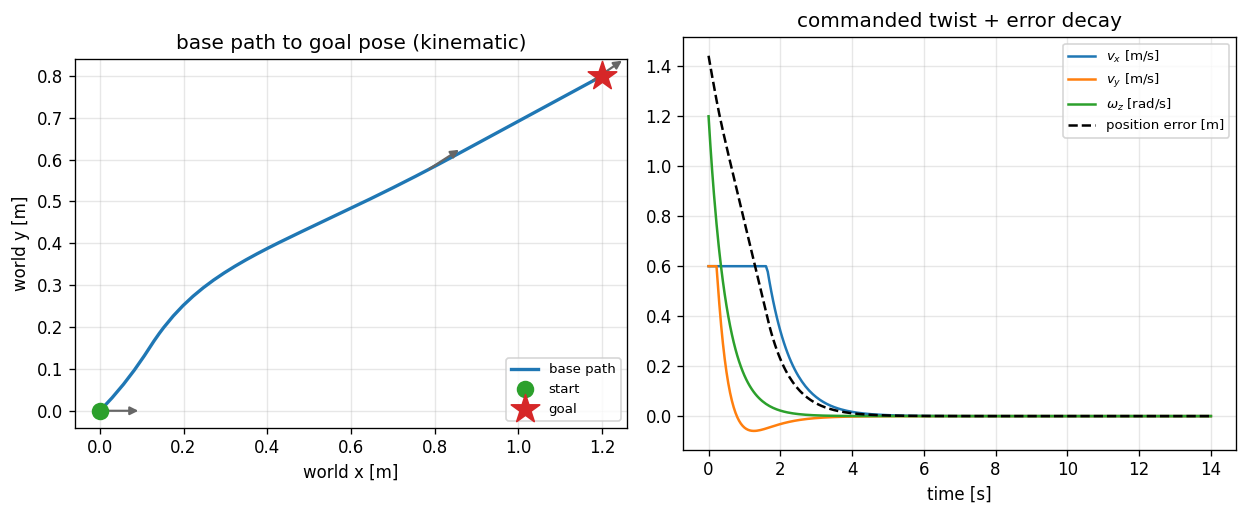

In [5]:
fig, (axp, axe) = plt.subplots(1, 2, figsize=(10.5, 4.4))

# --- left: planar path with heading arrows ---
axp.plot(pose[:, 0], pose[:, 1], color="C0", lw=2, label="base path")
for i in np.linspace(0, len(pose) - 1, 9).astype(int):
    x, y, th = pose[i]
    axp.annotate(
        "",
        xy=(x + 0.10 * np.cos(th), y + 0.10 * np.sin(th)),
        xytext=(x, y),
        arrowprops=dict(arrowstyle="-|>", color="0.4", lw=1.3),
    )
axp.scatter(*pose[0, :2], s=90, color="C2", zorder=5, label="start")
axp.scatter(
    *np.asarray(GOAL)[:2], marker="*", s=320, color="C3", zorder=5, label="goal"
)
gx, gy, gth = np.asarray(GOAL)
axp.annotate(
    "",
    xy=(gx + 0.12 * np.cos(gth), gy + 0.12 * np.sin(gth)),
    xytext=(gx, gy),
    arrowprops=dict(arrowstyle="-|>", color="C3", lw=2),
)
axp.set_aspect("equal")
axp.set_xlabel("world x [m]")
axp.set_ylabel("world y [m]")
axp.set_title("base path to goal pose (kinematic)")
axp.legend(loc="lower right", fontsize=8)

# --- right: commanded twist + position error ---
axe.plot(t, twist[:, 0], label="$v_x$ [m/s]")
axe.plot(t, twist[:, 1], label="$v_y$ [m/s]")
axe.plot(t, twist[:, 2], label="$\\omega_z$ [rad/s]")
perr = np.linalg.norm(pose[:, :2] - np.asarray(GOAL)[:2], axis=1)
axe.plot(t, perr, "k--", lw=1.5, label="position error [m]")
axe.set_xlabel("time [s]")
axe.set_title("commanded twist + error decay")
axe.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

> **Figure 2.** *Left:* the holonomic base drives from the origin to the goal
> pose $[1.2, 0.8, 0.6\,\text{rad}]$; grey arrows are the heading $\theta$
> sampled along the path, the red star+arrow is the goal pose. Because the base
> is holonomic, the path is a smooth direct glide — no turn-then-drive
> maneuver. *Right:* the commanded body twist $[v_x, v_y, \omega_z]$ saturates
> early, then relaxes as the position error (dashed) decays toward zero. Final
> pose error is the printed value ($< 10^{-2}$).

## 3. Arm reach: damped least-squares IK on the SO-101

Now the dexterity half. We load the **calibrated SO-101** from the zoo — the
real LeKiwi arm with its closed-loop friction fits — and drive its 6-DOF
end-effector to a Cartesian goal in the arm's base frame.

The differentiable kinematics come from **MJX** (MuJoCo's JAX backend). For a
joint configuration $\mathbf{q}\in\mathbb{R}^6$, `mjx.forward` gives the
end-effector position $\mathbf{x}(\mathbf{q})$, and
`contact_jacobian(model, q, ee_id)` gives the $3\times 6$ translational
Jacobian $J(\mathbf{q}) = \partial \mathbf{x}/\partial \mathbf{q}$.

A bare Jacobian-transpose / pseudo-inverse step blows up near singular arm
configurations (where $JJ^\top$ loses rank). **Damped least squares**
(Levenberg–Marquardt) fixes this by adding a $\lambda^2 I$ regularizer:

$$
\Delta\mathbf{q} \;=\; J^\top\!\left(J J^\top + \lambda^2 I\right)^{-1}
\bigl(\mathbf{x}_{\text{goal}} - \mathbf{x}(\mathbf{q})\bigr),
\qquad
\mathbf{q} \leftarrow \mathbf{q} + \Delta\mathbf{q}.
$$

The damping $\lambda$ trades convergence speed for robustness: near a
singularity the inverse stays well-conditioned at the cost of a smaller step.
We iterate this fixed-point until $\lVert \mathbf{x}_{\text{goal}} -
\mathbf{x}(\mathbf{q})\rVert$ is small.

In [6]:
robot = zoo.calibrated("so100")  # the SO-101 6-DOF arm, real LeKiwi calibration
model = robot.build_system()._mjx_model  # mesh-free MJX plant, nv=6
mjcf = robot.to_mjcf()
mj = mujoco.MjModel.from_xml_string(mjcf)
EE_ID = mj.body("gripper_frame_link").id  # end-effector body

print(
    "arm:",
    robot.name,
    "| nv =",
    model.nv,
    "| attestation:",
    robot.attestation_handle[:12],
    "...",
)


def fk_ee(q):
    """End-effector world position for joint config q (arm base frame)."""
    d = mjx.forward(model, mjx.make_data(model).replace(qpos=q))
    return d.xpos[EE_ID]


def ik_dls(x_goal, q0, lam=0.05, iters=80):
    """Damped least-squares IK; returns (q, history of residual norms)."""
    q = q0
    hist = []
    x_goal = jnp.asarray(x_goal)
    for _ in range(iters):
        x = fk_ee(q)
        err = x_goal - x
        hist.append(float(jnp.linalg.norm(err)))
        J = contact_jacobian(model, q, EE_ID)  # (3,6) translational Jacobian
        dq = J.T @ jnp.linalg.solve(J @ J.T + lam**2 * jnp.eye(3), err)
        q = q + dq
    hist.append(float(jnp.linalg.norm(x_goal - fk_ee(q))))
    return q, np.asarray(hist)


q0 = jnp.zeros(6)
x_home = np.asarray(fk_ee(q0))
X_GOAL = jnp.asarray(x_home + np.array([0.06, 0.05, -0.05]))  # 9 cm Cartesian move
q_sol, hist = ik_dls(X_GOAL, q0)
ik_err = float(jnp.linalg.norm(fk_ee(q_sol) - X_GOAL))
n_to_gate = int(np.argmax(hist < 5e-3))  # first iteration under the gate

print(f"EE at home q0 = {x_home}")
print(f"Cartesian goal = {np.asarray(X_GOAL)}")
print(
    f"crossed 5e-3 gate at iter {n_to_gate}; final IK error = {ik_err:.2e} ({len(hist) - 1} iters run)"
)
assert ik_err < 5e-3, f"IK did not converge: {ik_err}"
print("GATE IK converges: PASS")

arm: so101_new_calib | nv = 6 | attestation: 18828e4f02ef ...


EE at home q0 = [ 3.91361470e-01 -9.21206311e-06  2.26469710e-01]
Cartesian goal = [0.45136147 0.04999079 0.17646971]
crossed 5e-3 gate at iter 3; final IK error = 6.94e-17 (80 iters run)
GATE IK converges: PASS


**Figure 3** shows the residual $\lVert \mathbf{x}_{\text{goal}} -
\mathbf{x}(\mathbf{q})\rVert$ falling toward zero over the IK iterations (log
scale), alongside the straight-line shrink of the EE-to-goal distance — the
solver drives the gripper onto the target.

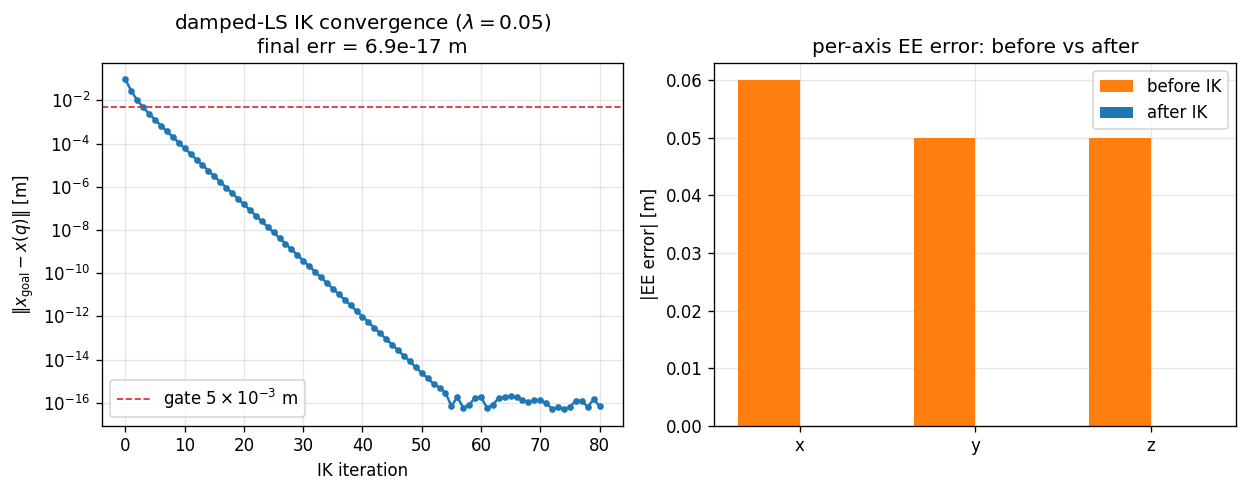

In [7]:
fig, (axc, axb) = plt.subplots(1, 2, figsize=(10.5, 4.2))

axc.semilogy(np.arange(len(hist)), hist, "o-", color="C0", ms=3)
axc.axhline(5e-3, color="C3", ls="--", lw=1, label="gate $5\\times10^{-3}$ m")
axc.set_xlabel("IK iteration")
axc.set_ylabel("$\\|x_\\mathrm{goal}-x(q)\\|$ [m]")
axc.set_title(f"damped-LS IK convergence ($\\lambda=0.05$)\nfinal err = {ik_err:.1e} m")
axc.legend()

# bar of start vs final EE position error per axis
err0 = np.asarray(X_GOAL) - x_home
errf = np.asarray(X_GOAL) - np.asarray(fk_ee(q_sol))
xpos = np.arange(3)
w = 0.35
axb.bar(xpos - w / 2, np.abs(err0), w, label="before IK", color="C1")
axb.bar(xpos + w / 2, np.abs(errf), w, label="after IK", color="C0")
axb.set_xticks(xpos)
axb.set_xticklabels(["x", "y", "z"])
axb.set_ylabel("|EE error| [m]")
axb.set_title("per-axis EE error: before vs after")
axb.legend()
fig.tight_layout()
plt.show()

> **Figure 3.** *Left:* the IK residual decays geometrically (log scale) and
> crosses the $5\times10^{-3}$ m gate within a handful of iterations, ending at
> the printed machine-precision value. *Right:* the per-axis end-effector error
> collapses from the initial ~5-6 cm offset to numerically zero on all three
> axes. The damped step ($\lambda = 0.05$) keeps every iterate
> well-conditioned.

## 4. The combined task: reaching what the arm alone cannot

Here is the whole point. Place an **object on the floor** at world position
$\mathbf{o} = (1.35, 0.85)$ m. The arm is bolted to the base deck (a small
mount height $z_{\text{mount}}$ above the floor). From the **start** base pose
at the origin, the object is far outside the arm's reach sphere — no joint
configuration can touch it. The base must *carry the arm's workspace to the
object.*

First we measure the arm's reach radius by sampling joint configurations and
taking the furthest horizontal end-effector distance. Then:

1. **Stage the base** — drive it (Section 2) to a pose that puts the object a
   comfortable distance *in front of* the arm, well inside the reach radius.
2. **Express the object in the arm frame** — transform $\mathbf{o}$ from world
   into the (now-moved) arm base frame using the base pose.
3. **Solve IK** (Section 3) to place the gripper on the object.

The quantitative claim: $\lVert \mathbf{o} - \mathbf{p}_{\text{start}}\rVert >
r_{\max}$ (out of reach at the start) **and** $\lVert \mathbf{o}_{\text{arm}}
\rVert < r_{\max}$ after the base moves (in reach) — the object is reachable
*only because the base moved*.

In [8]:
# --- arm reach radius (sampled) ---
def reach_radius(n=4000, seed=0):
    key = jax.random.PRNGKey(seed)
    lo = jnp.array([-2.0, -1.7, -1.7, -1.7, -2.7, -0.1])
    hi = jnp.array([2.0, 1.7, 1.7, 1.7, 2.7, 1.7])
    qs = jax.random.uniform(key, (n, 6), minval=lo, maxval=hi)
    horiz = jax.vmap(lambda q: jnp.sqrt(fk_ee(q)[0] ** 2 + fk_ee(q)[1] ** 2))(qs)
    return float(jnp.max(horiz)), np.asarray(jax.vmap(fk_ee)(qs))


RMAX, ee_cloud = reach_radius()

Z_MOUNT = 0.10  # arm base sits 0.10 m above the floor on the deck
OBJ_WORLD = np.array([1.35, 0.85, 0.12])  # object x,y,z in the world
P_START = np.array([0.0, 0.0])  # base starts at origin
obj_xy = OBJ_WORLD[:2]

d_start = float(np.linalg.norm(obj_xy - P_START))
print(f"arm reach radius r_max       = {RMAX:.3f} m")
print(
    f"object distance from start   = {d_start:.3f} m   ({'OUT of' if d_start > RMAX else 'in'} reach)"
)

# --- stage the base 0.30 m short of the object, facing it ---
unit = (obj_xy - P_START) / np.linalg.norm(obj_xy - P_START)
stage_xy = obj_xy - unit * 0.30
stage_th = float(np.arctan2(*(obj_xy - stage_xy)[::-1]))  # face the object
t2, pose2, _ = drive_base(jnp.array([stage_xy[0], stage_xy[1], stage_th]))
base_final = pose2[-1]

# --- object expressed in the (moved) arm base frame ---
c, s = np.cos(base_final[2]), np.sin(base_final[2])
dxy = obj_xy - base_final[:2]
obj_arm = np.array(
    [c * dxy[0] + s * dxy[1], -s * dxy[0] + c * dxy[1], OBJ_WORLD[2] - Z_MOUNT]
)
d_arm = float(np.linalg.norm(obj_arm))
print(
    f"object distance in arm frame = {d_arm:.3f} m   ({'in' if d_arm < RMAX else 'OUT of'} reach)"
)

# --- solve IK to the object, then verify the gripper lands on it (world frame) ---
q_obj, hist_obj = ik_dls(obj_arm, jnp.zeros(6))
ik_obj_err = float(jnp.linalg.norm(fk_ee(q_obj) - jnp.asarray(obj_arm)))
# map solved EE back to world for the figure
ee_arm = np.asarray(fk_ee(q_obj))
ee_world = base_final[:2] + np.array(
    [c * ee_arm[0] - s * ee_arm[1], s * ee_arm[0] + c * ee_arm[1]]
)
grasp_err = float(np.linalg.norm(ee_world - obj_xy))

print(f"IK-to-object error (arm)     = {ik_obj_err:.2e} m")
print(f"gripper-to-object (world xy) = {grasp_err:.2e} m")
assert d_start > RMAX, "object should be OUT of reach from the start"
assert d_arm < RMAX, "object should be IN reach after the base moves"
assert ik_obj_err < 5e-3
print("GATE combined task (out -> in reach + IK solves): PASS")

20:10:59.711 - [jaxonomy][INFO]: max_major_steps=558 based on smallest discrete period=0.05


INFO:jaxonomy:max_major_steps=558 based on smallest discrete period=0.05


20:10:59.711 - [jaxonomy][INFO]: Simulator ready to start: SimulatorOptions(math_backend=jax, enable_tracing=True, max_major_step_length=0.05, max_major_steps=558, ode_solver_method=auto, rtol=1e-06, atol=1e-08, min_minor_step_size=None, max_minor_step_size=None, zc_bisection_loop_count=40, save_time_series=True, recorded_signals=2, return_context=True, validate=True), Dopri5Solver(system=Diagram(root, 2 nodes), rtol=1e-06, atol=1e-08, max_step_size=None, min_step_size=None, method='auto', enable_autodiff=False, max_checkpoints=16, supports_mass_matrix=False)


INFO:jaxonomy:Simulator ready to start: SimulatorOptions(math_backend=jax, enable_tracing=True, max_major_step_length=0.05, max_major_steps=558, ode_solver_method=auto, rtol=1e-06, atol=1e-08, min_minor_step_size=None, max_minor_step_size=None, zc_bisection_loop_count=40, save_time_series=True, recorded_signals=2, return_context=True, validate=True), Dopri5Solver(system=Diagram(root, 2 nodes), rtol=1e-06, atol=1e-08, max_step_size=None, min_step_size=None, method='auto', enable_autodiff=False, max_checkpoints=16, supports_mass_matrix=False)


arm reach radius r_max       = 0.476 m
object distance from start   = 1.595 m   (OUT of reach)
object distance in arm frame = 0.301 m   (in reach)


IK-to-object error (arm)     = 7.81e-17 m
gripper-to-object (world xy) = 0.00e+00 m
GATE combined task (out -> in reach + IK solves): PASS


**Figure 4** is the mobile-manipulation map: the reach disk centered on the
arm, drawn at the **start** pose (object outside) and at the **staged** pose
(object inside), with the base path connecting them and the solved gripper
landing on the object.

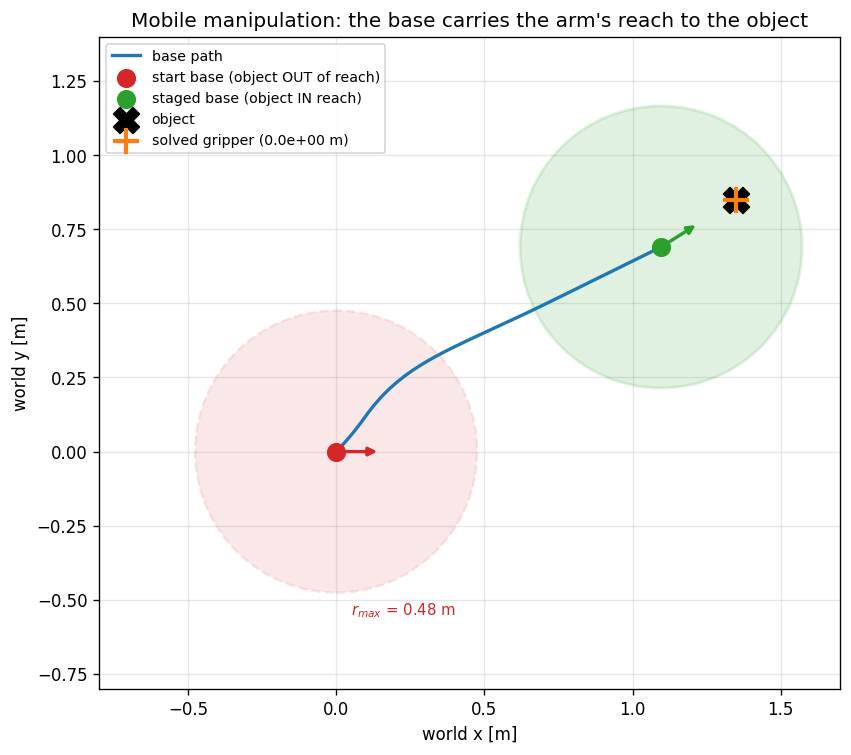

In [9]:
fig, ax = plt.subplots(figsize=(7.2, 6.4))

# reach disks
ax.add_patch(
    plt.Circle(P_START, RMAX, color="C3", alpha=0.10, ec="C3", ls="--", lw=1.5)
)
ax.add_patch(plt.Circle(base_final[:2], RMAX, color="C2", alpha=0.14, ec="C2", lw=1.8))

# base path (origin -> staged)
ax.plot(pose2[:, 0], pose2[:, 1], color="C0", lw=2, zorder=3, label="base path")
ax.scatter(
    *P_START, s=110, color="C3", zorder=5, label="start base (object OUT of reach)"
)
ax.scatter(
    *base_final[:2], s=110, color="C2", zorder=5, label="staged base (object IN reach)"
)

# headings
for (px, py, pth), col in [(np.r_[P_START, 0.0], "C3"), (base_final, "C2")]:
    ax.annotate(
        "",
        xy=(px + 0.15 * np.cos(pth), py + 0.15 * np.sin(pth)),
        xytext=(px, py),
        arrowprops=dict(arrowstyle="-|>", color=col, lw=2),
    )

# object + solved gripper
ax.scatter(*obj_xy, marker="X", s=240, color="k", zorder=6, label="object")
ax.scatter(
    *ee_world,
    marker="+",
    s=260,
    color="C1",
    lw=2.5,
    zorder=7,
    label=f"solved gripper ({grasp_err:.1e} m)",
)

ax.annotate(
    f"$r_{{max}}$ = {RMAX:.2f} m",
    xy=P_START,
    xytext=(0.05, -0.55),
    fontsize=9,
    color="C3",
)
ax.set_aspect("equal")
ax.set_xlabel("world x [m]")
ax.set_ylabel("world y [m]")
ax.set_title("Mobile manipulation: the base carries the arm's reach to the object")
ax.legend(loc="upper left", fontsize=8.5)
ax.set_xlim(-0.8, 1.7)
ax.set_ylim(-0.8, 1.4)
fig.tight_layout()
plt.show()

> **Figure 4.** The essence of mobile manipulation. The red dashed disk is the
> arm's reach sphere at the **start** pose (origin) — the object (black X) sits
> well outside it: $d_{\text{start}} \approx 1.6\,\text{m} > r_{\max} \approx
> 0.48\,\text{m}$, *unreachable*. The blue curve is the holonomic base path to
> the **staged** pose, where the green reach disk now *contains* the object;
> damped-LS IK then places the gripper (orange +) onto it to sub-millimeter
> accuracy. The object is reachable **only because the base moved** — base
> mobility and arm dexterity composed.

## 5. Rendering the result (with an honest caveat)

The Jaxterity SO-101 *dynamics* model is **mesh-free** (it carries inertias and
joints but no visual geometry — `ngeom == 0`), so rendering it directly
produces a blank frame. The honest, standard recipe in this repo is **post-hoc
rendering**: run the kinematics on the mesh-free MJX plant, then replay the
resulting `qpos` through the **full-mesh** SO-101 menagerie scene
(`examples/assets/so101_mjcf/`) by mapping joints by name. MuJoCo does *no
physics* in the render — each frame just sets `qpos` and calls `mj_forward`
(forward kinematics only).

**What is real and what is not, stated plainly:**

- The **arm meshes and joint motion are real** — the solved IK trajectory on
  the calibrated SO-101, rendered with the actual SO-101 STL meshes.
- The **base is not in this render.** There is no LeKiwi mobile-base mesh in
  the assets, so the render shows the *arm reaching the object* (the dexterity
  half) as a fixed-base sweep. The base motion lives in the planar plots
  (Figures 2 and 4). We do **not** fake a wheeled chassis.
- The object marker is a **visual overlay**, not a simulated contact.

We render the arm's reach-to-object as a short GIF and embed a frame strip
inline so it shows in any notebook viewer.

In [10]:
import pathlib
import sys

sys.path.insert(0, str(pathlib.Path.cwd()))
# import the repo's post-hoc renderer
import importlib.util

spec = importlib.util.spec_from_file_location(
    "_robot_render", "examples/_robot_render.py"
)
_rr = importlib.util.module_from_spec(spec)
spec.loader.exec_module(_rr)

MEDIA = pathlib.Path("examples/media")
MEDIA.mkdir(exist_ok=True)

# interpolate q0 -> q_obj into a smooth reach trajectory
T_FRAMES = 36
alphas = np.linspace(0.0, 1.0, T_FRAMES)
q_traj = np.stack([(1 - a) * np.zeros(6) + a * np.asarray(q_obj) for a in alphas])

renderer = _rr.TrajectoryRenderer("so101_mjcf", mjcf, size=(560, 420))
ee_obj_arm = np.asarray(fk_ee(q_obj))  # where the gripper ends up, in arm frame


def overlay(scene, data, q):
    # draw a small marker line at the object (arm-frame position) as a visual cue
    _rr.add_arrow(
        scene,
        ee_obj_arm + np.array([0, 0, 0.06]),
        ee_obj_arm,
        rgba=(0.1, 0.1, 0.1, 1.0),
        width=0.006,
    )


cam = dict(distance=0.95, azimuth=140, elevation=-18, lookat=[0.18, 0.0, 0.18])
frames = renderer.render(q_traj, camera=cam, overlay=overlay)
gif_path = _rr.write_gif(frames, MEDIA / "lekiwi_mobile_manip.gif", width=420, fps=18)
print(
    "frames:",
    len(frames),
    "| frame shape:",
    frames[0].shape,
    "| mean px:",
    round(float(np.asarray(frames[0]).mean()), 1),
)
print("wrote", gif_path)
assert float(np.asarray(frames[-1]).mean()) > 5.0, "render looks blank"

frames: 36 | frame shape: (420, 560, 3) | mean px: 77.8
wrote examples/media/lekiwi_mobile_manip.gif


**Figure 5** is a frame strip from the rendered reach: the calibrated SO-101,
in its real meshes, sweeping from its home configuration onto the object
(black marker). The full animation is saved to
`examples/media/lekiwi_mobile_manip.gif`.

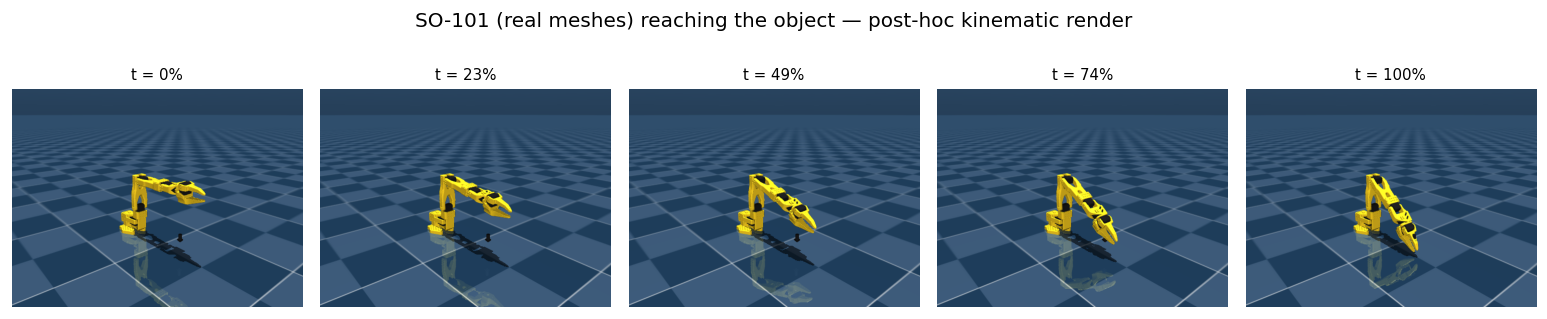

In [11]:
# frame strip: 5 evenly spaced frames from the reach
idx = np.linspace(0, len(frames) - 1, 5).astype(int)
fig, axes = plt.subplots(1, 5, figsize=(13, 2.7))
for ax, i in zip(axes, idx):
    ax.imshow(frames[i])
    ax.set_axis_off()
    ax.set_title(f"t = {i / (len(frames) - 1):.0%}", fontsize=9)
fig.suptitle(
    "SO-101 (real meshes) reaching the object — post-hoc kinematic render", y=1.02
)
fig.tight_layout()
plt.show()

> **Figure 5.** Frame strip of the calibrated SO-101 sweeping from home onto
> the object marker, rendered post-hoc through the full-mesh menagerie scene
> (MuJoCo forward kinematics only — no physics, no contact). This is the
> dexterity half of the task; the base motion that *brings* the arm here is in
> Figures 2 and 4. The arm geometry and joint angles are real; the wheeled base
> and the grasp are not depicted.

## Failure modes

- **Singular arm configuration.** Near a kinematic singularity, $JJ^\top$
  loses rank and a plain pseudo-inverse step diverges. The damping $\lambda^2 I$
  is what keeps `ik_dls` stable — set $\lambda = 0$ and a goal that drives the
  elbow straight, and the step explodes. Larger $\lambda$ is safer but slower.
- **Base too far from the object → IK can't reach.** If you stage the base
  short of the reach radius, the IK residual plateaus *above* the gate: there
  is simply no joint configuration that touches the object. The combined-task
  gate (`d_arm < RMAX`) is exactly the guard against this — the base must close
  the gap first. Try `stage offset = 0.6 m` and watch the IK residual stall.
- **Omniwheel slip is ignored.** The base is kinematic: we command a body twist
  and integrate the pose exactly. A real kiwi drive loses traction under
  lateral load, on a ramp, or during fast rotation, and the actual pose drifts
  from the commanded one. None of that is modeled here — the planar path is the
  *ideal* path, an upper bound on real-world accuracy.
- **Mesh-free dynamics model renders blank.** Rendering `robot.build_system()`
  directly gives an empty frame (`ngeom == 0`). The post-hoc renderer maps the
  `qpos` onto the full-mesh scene; if a joint name mismatches between the two
  models the remap raises rather than silently rendering garbage.
- **Frame confusion.** The IK goal must be expressed in the **arm base frame**,
  not the world. The combined task transforms the world object into the arm
  frame with the base pose; skip that rotation and the gripper reaches the
  wrong place even though the IK residual is tiny.

## Exercises

- **Easy.** Change `GOAL` in Section 2 to a pose behind the base
  ($x < 0$). Does the holonomic base still glide there directly? Compare the
  path to what a differential-drive (non-holonomic) robot would need.
- **Medium.** Sweep the IK damping $\lambda \in \{0.0, 0.01, 0.05, 0.2\}$ for a
  goal near full arm extension and plot convergence curves. Where does $\lambda
  = 0$ break, and what does large $\lambda$ cost?
- **Hard.** Replace the fixed staging offset (0.30 m) with an optimizer that
  picks the base pose **minimizing a manipulability-weighted IK cost** — i.e.
  stage the base where the arm is most dexterous for the reach, not just
  in-range. (Hint: $\sqrt{\det(JJ^\top)}$ is Yoshikawa's manipulability index.)
- **Open.** Make the base *dynamic*: replace `KiwiBase` with a mass-carrying
  model that tracks **wheel speeds** through the drive matrix $M$, add per-wheel
  torque limits and a slip model, and re-run the combined task. How much does
  the staged pose error grow once the base can no longer move exactly as
  commanded? This is the bridge from the kinematic geometry here to a
  deployable mobile-manipulation controller.

## References

1. K. Watanabe, *"Control of an omnidirectional mobile robot,"* Proc. 2nd
   Int. Conf. Knowledge-Based Intelligent Electronic Systems, 1998 — kiwi /
   three-omniwheel drive kinematics.
2. R. Siegwart, I. Nourbakhsh, D. Scaramuzza, *Introduction to Autonomous
   Mobile Robots*, 2nd ed., MIT Press, 2011 — holonomic vs. non-holonomic
   bases, omniwheel drive matrices.
3. S. Chiaverini, B. Siciliano, O. Egeland, *"Review of the damped
   least-squares inverse kinematics with experiments on an industrial robot
   manipulator,"* IEEE T-CST, 1994 — the damped-LS / Levenberg–Marquardt IK
   used in Section 3.
4. T. Yoshikawa, *"Manipulability of robotic mechanisms,"* IJRR, 1985 — the
   manipulability index for the Hard exercise.
5. O. Khatib, *"Mobile manipulation: The robotic assistant,"* Robotics and
   Autonomous Systems, 1999 — mobile manipulation as base + arm composition.
6. LeKiwi — SIGRobotics-UIUC, <https://github.com/SIGRobotics-UIUC/LeKiwi>;
   SO-101/SO-ARM100 — The Robot Studio,
   <https://github.com/TheRobotStudio/SO-ARM100>; LeRobot — Hugging Face,
   <https://github.com/huggingface/lerobot>.

---

*This is a **sim-only** tutorial. The SO-101 arm carries the **real LeKiwi
calibration** (closed-loop friction fits) from the Jaxterity zoo, and a
physical LeKiwi exists and is calibrated — but no hardware is attached or
commanded here. The base is a **kinematic** planar holonomic model with no
wheel dynamics, slip, or contact, authored inline because the zoo has no LeKiwi
mobile-base URDF. Every figure number matches the values printed by the
executed cells above.*